# Home Credit Default Risk Prediction

**Ders:** BYM447 – Makine Öğrenmesi

**Proje Türü:** Bireysel Makine Öğrenmesi Projesi

**Veri Seti:** Home Credit Default Risk

**Problem Türü:** İkili Sınıflandırma (Binary Classification)

**Hedef Değişken:** `TARGET`

**Veri Kaynağı:** [Kaggle – Home Credit Default Risk](https://www.kaggle.com/competitions/home-credit-default-risk/data)

---

## 1. Giriş ve Problem Tanımı

### 1.1. Problem Tanımı

Bu çalışmada, Home Credit Default Risk veri seti kullanılarak kredi başvurusunda bulunan bireylerin geri ödeme güçlüğü yaşama durumlarının makine öğrenmesi yöntemleriyle tahmin edilmesi amaçlanmaktadır.

Çalışma, ikili sınıflandırma problemi olarak ele alınmıştır. Tahmin edilmek istenen durum, veri setindeki `TARGET` değişkeni ile temsil edilmektedir.

### 1.2. Projenin Amacı

Projenin temel amacı, farklı makine öğrenmesi algoritmalarını kullanarak kredi geri ödeme güçlüğü tahmininde bulunmak ve bu algoritmaların performanslarını karşılaştırmaktır.

Bu kapsamda veri seti üzerinde keşifsel veri analizi, veri ön işleme, model geliştirme, model değerlendirme ve hata analizi çalışmaları gerçekleştirilecektir.

### 1.3. Başarı Ölçütleri

Modellerin performansları Accuracy, Precision, Recall, F1-score ve ROC-AUC metrikleri kullanılarak değerlendirilecektir. Ayrıca sınıflandırma sonuçlarının ayrıntılı incelenmesi amacıyla Confusion Matrix kullanılacaktır.

Sınıf dengesizliği dikkate alınarak Accuracy metriği tek başına yeterli bir başarı ölçütü olarak kabul edilmeyecektir.

## 2. Veri Setinin Yüklenmesi ve İlk İnceleme

In [1]:
# Temel veri analizi kütüphaneleri
import pandas as pd
import numpy as np

# Görselleştirme kütüphaneleri
import matplotlib.pyplot as plt
import seaborn as sns

# Dosya ve sistem işlemleri
from pathlib import Path

# Grafik ayarları
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Rastgelelik kontrolü
RANDOM_STATE = 42

print("Kütüphaneler başarıyla yüklendi.")

Kütüphaneler başarıyla yüklendi.


### 2.1. Veri Setinin Yüklenmesi

In [2]:
# Veri dosyasının yolu
DATA_DIR = Path("../data")

TRAIN_PATH = DATA_DIR / "application_train.csv"
DESCRIPTION_PATH = DATA_DIR / "HomeCredit_columns_description.csv"

# Dosya kontrolü
if not TRAIN_PATH.exists():
    raise FileNotFoundError(f"Veri dosyası bulunamadı: {TRAIN_PATH}")

if not DESCRIPTION_PATH.exists():
    raise FileNotFoundError(
        f"Sütun açıklama dosyası bulunamadı: {DESCRIPTION_PATH}"
    )

# Ana veri setini yükleme
df = pd.read_csv(TRAIN_PATH)

print("Veri seti başarıyla yüklendi.")

Veri seti başarıyla yüklendi.


### 2.2. Veri Setinin Genel Yapısı

In [3]:
# Satır ve sütun sayısı
print(f"Satır sayısı: {df.shape[0]:,}")
print(f"Sütun sayısı: {df.shape[1]:,}")

# İlk beş gözlem
display(df.head())

# Son beş gözlem
display(df.tail())

Satır sayısı: 307,511
Sütun sayısı: 122


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
307510,456255,0,Cash loans,F,N,N,0,157500.0,675000.0,49117.5,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,1.0


In [4]:
# Veri setinin boyutu
print("Veri setinin boyutu:", df.shape)

# Toplam satır ve sütun sayısı
print(f"Toplam gözlem sayısı: {df.shape[0]:,}")
print(f"Toplam değişken sayısı: {df.shape[1]}")

# Veri tiplerinin dağılımı
print("\nVeri tiplerinin dağılımı:")
display(df.dtypes.value_counts())

# Bellek kullanımı
memory_usage = df.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"\nBellek kullanımı: {memory_usage:.2f} MB")

Veri setinin boyutu: (307511, 122)
Toplam gözlem sayısı: 307,511
Toplam değişken sayısı: 122

Veri tiplerinin dağılımı:


float64    65
int64      41
str        16
Name: count, dtype: int64


Bellek kullanımı: 536.69 MB


In [5]:
# Veri setindeki değişkenlerin genel incelemesi

column_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.notna().sum(),
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

display(column_summary)

print("\nSayısal değişken sayısı:",
      df.select_dtypes(include="number").shape[1])

print("Kategorik değişken sayısı:",
      df.select_dtypes(include=["object", "str", "category"]).shape[1])

print("\nHedef değişken mevcut mu:", "TARGET" in df.columns)
print("Hedef değişken değerleri:", df["TARGET"].unique())

,Data Type,Non-Null Count,Missing Count,Missing Percentage,Unique Values
SK_ID_CURR,int64,307511,0,0.0,307511
TARGET,int64,307511,0,0.0,2
NAME_CONTRACT_TYPE,str,307511,0,0.0,2
CODE_GENDER,str,307511,0,0.0,3
FLAG_OWN_CAR,str,307511,0,0.0,2
...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,float64,265992,41519,13.5,9
AMT_REQ_CREDIT_BUREAU_WEEK,float64,265992,41519,13.5,9
AMT_REQ_CREDIT_BUREAU_MON,float64,265992,41519,13.5,24
AMT_REQ_CREDIT_BUREAU_QRT,float64,265992,41519,13.5,11



Sayısal değişken sayısı: 106
Kategorik değişken sayısı: 16

Hedef değişken mevcut mu: True
Hedef değişken değerleri: [1 0]


### 2.4. Değişken Açıklamalarının İncelenmesi

In [6]:
# Sütun açıklama dosyasını yükleme
description_df = pd.read_csv(
    DESCRIPTION_PATH,
    encoding="latin1"
)

print("Sütun açıklama dosyasının boyutu:", description_df.shape)

# Veri sözlüğünün ilk kayıtları
display(description_df.head(10))

# Sütun isimleri
print("\nVeri sözlüğündeki sütunlar:")
print(description_df.columns.tolist())

Sütun açıklama dosyasının boyutu: (219, 5)


,Unnamed: 0,Table,Row,Description,Special
0,1,application_{train|test}.csv,SK_ID_CURR,ID of loan in our sample,NaN
1,2,application_{train|test}.csv,TARGET,Target variable (1 - client with payment diffi...,NaN
2,5,application_{train|test}.csv,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,6,application_{train|test}.csv,CODE_GENDER,Gender of the client,NaN
4,7,application_{train|test}.csv,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,8,application_{train|test}.csv,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
6,9,application_{train|test}.csv,CNT_CHILDREN,Number of children the client has,NaN
7,10,application_{train|test}.csv,AMT_INCOME_TOTAL,Income of the client,NaN
8,11,application_{train|test}.csv,AMT_CREDIT,Credit amount of the loan,NaN
9,12,application_{train|test}.csv,AMT_ANNUITY,Loan annuity,NaN



Veri sözlüğündeki sütunlar:
['Unnamed: 0', 'Table', 'Row', 'Description', 'Special']


In [7]:
# Ana veri setindeki değişkenlerin açıklamalarını eşleştirme

# application_train ve application_test açıklamalarını filtrele
application_descriptions = description_df[
    description_df["Table"].str.contains(
        "application_", case=False, na=False
    )
].copy()

# Açıklama sütunlarının isimlerini düzenle
application_descriptions = application_descriptions.rename(
    columns={
        "Row": "Feature",
        "Description": "Meaning",
        "Special": "Notes"
    }
)

# Veri setinin değişken bilgilerini hazırla
feature_dictionary = column_summary.reset_index().rename(
    columns={"index": "Feature"}
)

# Veri sözlüğüyle birleştir
feature_dictionary = feature_dictionary.merge(
    application_descriptions[["Feature", "Meaning", "Notes"]],
    on="Feature",
    how="left"
)

# Sonuçları göster
display(feature_dictionary)

# Açıklaması bulunamayan değişkenleri kontrol et
unmatched = feature_dictionary[
    feature_dictionary["Meaning"].isna()
]

print("Toplam değişken:", len(feature_dictionary))
print("Açıklaması eşleşen değişken:",
      len(feature_dictionary) - len(unmatched))
print("Açıklaması bulunamayan değişken:", len(unmatched))

if not unmatched.empty:
    display(unmatched[["Feature"]])

,Feature,Data Type,Non-Null Count,Missing Count,Missing Percentage,Unique Values,Meaning,Notes
0,SK_ID_CURR,int64,307511,0,0.0,307511,ID of loan in our sample,NaN
1,TARGET,int64,307511,0,0.0,2,Target variable (1 - client with payment diffi...,NaN
2,NAME_CONTRACT_TYPE,str,307511,0,0.0,2,Identification if loan is cash or revolving,NaN
3,CODE_GENDER,str,307511,0,0.0,3,Gender of the client,NaN
4,FLAG_OWN_CAR,str,307511,0,0.0,2,Flag if the client owns a car,NaN
...,...,...,...,...,...,...,...,...
117,AMT_REQ_CREDIT_BUREAU_DAY,float64,265992,41519,13.5,9,Number of enquiries to Credit Bureau about the...,NaN
118,AMT_REQ_CREDIT_BUREAU_WEEK,float64,265992,41519,13.5,9,Number of enquiries to Credit Bureau about the...,NaN
119,AMT_REQ_CREDIT_BUREAU_MON,float64,265992,41519,13.5,24,Number of enquiries to Credit Bureau about the...,NaN
120,AMT_REQ_CREDIT_BUREAU_QRT,float64,265992,41519,13.5,11,Number of enquiries to Credit Bureau about the...,NaN


Toplam değişken: 122
Açıklaması eşleşen değişken: 122
Açıklaması bulunamayan değişken: 0


# 3. Keşifsel Veri Analizi (EDA)

## 3.1. Hedef Değişkenin Dağılımı

,Kayıt Sayısı,Oran (%)
0 - Geri ödeme güçlüğü gözlenmeyen,282686,91.93
1 - Geri ödeme güçlüğü gözlenen,24825,8.07


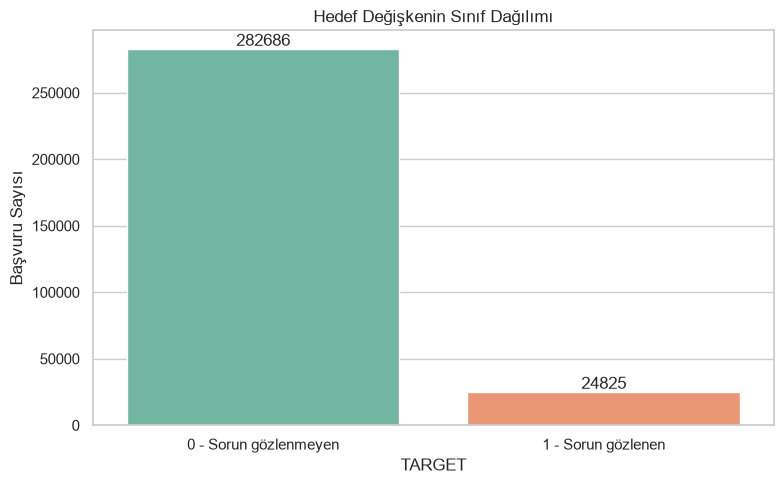

In [8]:
# Hedef değişkenin frekans ve yüzde dağılımları

target_summary = pd.DataFrame({
    "Kayıt Sayısı": df["TARGET"].value_counts().sort_index(),
    "Oran (%)": (
        df["TARGET"].value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

target_summary.index = [
    "0 - Geri ödeme güçlüğü gözlenmeyen",
    "1 - Geri ödeme güçlüğü gözlenen"
]

display(target_summary)

# Sınıf dağılımını görselleştirme
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="TARGET",
    hue="TARGET",
    palette="Set2",
    legend=False
)

plt.title("Hedef Değişkenin Sınıf Dağılımı")
plt.xlabel("TARGET")
plt.ylabel("Başvuru Sayısı")
plt.xticks([0, 1], ["0 - Sorun gözlenmeyen", "1 - Sorun gözlenen"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()

**Şekil 1. Hedef Değişkenin Sınıf Dağılımı**

Hedef değişkenin incelenmesi sonucunda veri setinde belirgin bir sınıf dengesizliği olduğu görülmüştür. Toplam 307.511 gözlemin 282.686'sı (%91,93) TARGET=0, 24.825'i (%8,07) ise TARGET=1 sınıfındadır. Bu dağılım, çoğunluk sınıfını tahmin eden bir modelin yanıltıcı derecede yüksek doğruluk elde edebilmesine neden olabilir. Bu nedenle model değerlendirmesinde Accuracy metriğinin tek başına kullanılmaması; Recall, Precision, F1-score ve ROC-AUC gibi metriklerin birlikte değerlendirilmesi planlanmıştır.

### 3.2. Eksik Değer Analizi

Eksik değer bulunan sütun: 67
Eksik değer bulunmayan sütun: 55
Toplam eksik hücre sayısı: 9,152,465
Genel eksik değer oranı: 24.40%


,Eksik Değer Sayısı,Eksik Değer Oranı (%)
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
COMMONAREA_AVG,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953


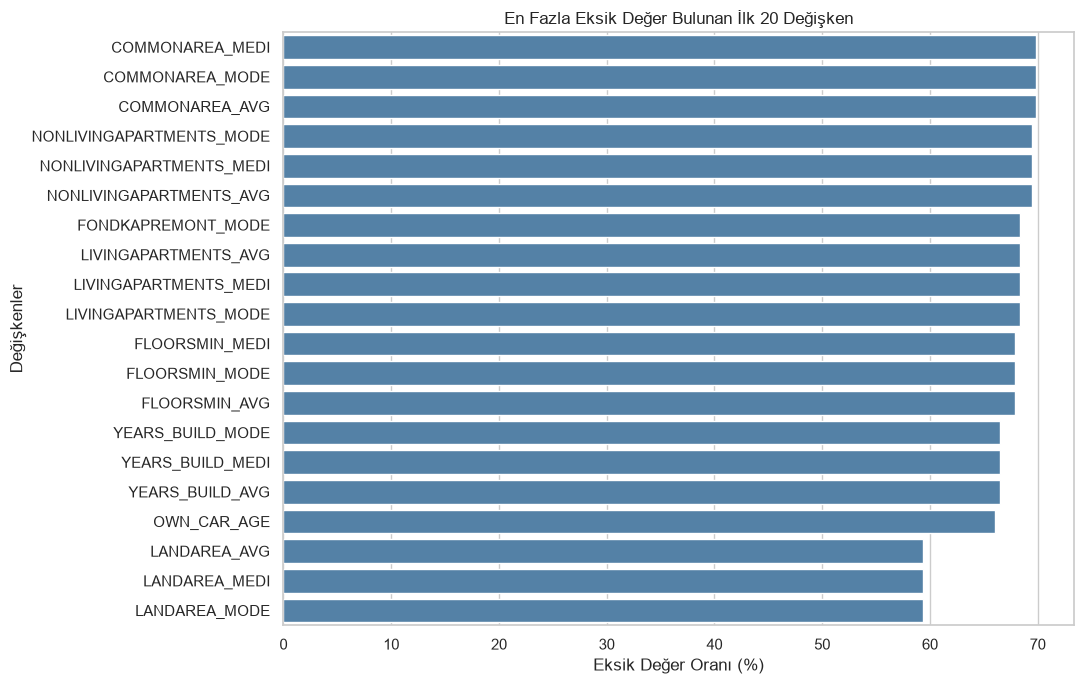

In [9]:
# Eksik değerlerin genel analizi

missing_summary = pd.DataFrame({
    "Eksik Değer Sayısı": df.isnull().sum(),
    "Eksik Değer Oranı (%)": df.isnull().mean() * 100
})

missing_summary = (
    missing_summary[missing_summary["Eksik Değer Sayısı"] > 0]
    .sort_values("Eksik Değer Oranı (%)", ascending=False)
)

print("Eksik değer bulunan sütun:", len(missing_summary))
print("Eksik değer bulunmayan sütun:", df.shape[1] - len(missing_summary))
print(
    f"Toplam eksik hücre sayısı: {df.isnull().sum().sum():,}"
)
print(
    f"Genel eksik değer oranı: {df.isnull().mean().mean() * 100:.2f}%"
)

display(missing_summary.head(20))

# En fazla eksik değer bulunan ilk 20 sütun
plt.figure(figsize=(11, 7))

sns.barplot(
    x=missing_summary.head(20)["Eksik Değer Oranı (%)"],
    y=missing_summary.head(20).index,
    color="steelblue"
)

plt.title("En Fazla Eksik Değer Bulunan İlk 20 Değişken")
plt.xlabel("Eksik Değer Oranı (%)")
plt.ylabel("Değişkenler")
plt.tight_layout()
plt.show()

**Şekil 2. En Fazla Eksik Değer Bulunan İlk 20 Değişken**

Eksik değer analizi sonucunda 122 değişkenin 67'sinde eksik gözlem bulunduğu belirlenmiştir. Veri setindeki toplam 9.152.465 hücre eksik olup genel eksik değer oranı %24,40'tır. En yüksek eksiklik oranları yaklaşık %69,87 ile COMMONAREA değişkeninin farklı gösterimlerinde görülmüştür. Eksikliklerin özellikle konut ve taşınmaz özelliklerini temsil eden değişkenlerde yoğunlaştığı gözlemlenmiştir. Bu durum, veri ön işleme aşamasında eksik değer stratejisinin dikkatle belirlenmesini gerekli kılmaktadır.

### 3.3. Eksik Değerlerin Veri Tiplerine Göre İncelenmesi

,Veri Tipi,Toplam Sütun,Eksik Değer İçeren Sütun,Eksik Hücre Sayısı,Eksik Hücre Oranı (%)
0,Sayısal,106,61,8388094,25.73
1,Kategorik,16,6,764371,15.54


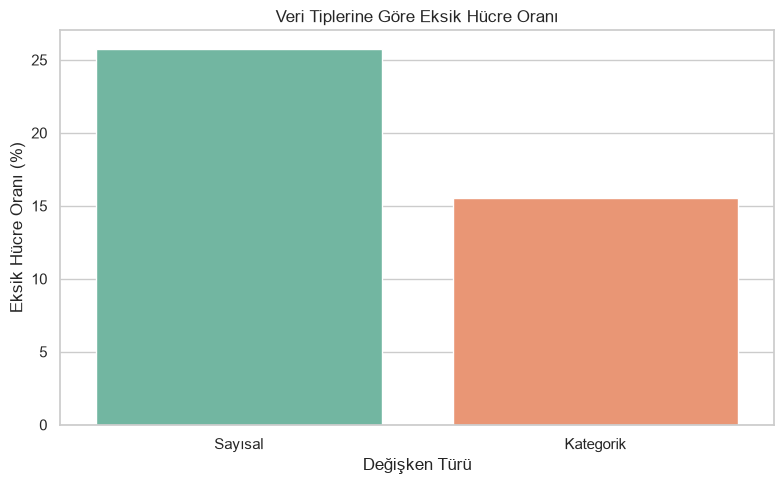

In [10]:
# Eksik değerleri veri tiplerine göre inceleme

numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include=["object", "str", "category"]).columns

missing_by_type = pd.DataFrame({
    "Veri Tipi": ["Sayısal", "Kategorik"],
    "Toplam Sütun": [len(numeric_cols), len(categorical_cols)],
    "Eksik Değer İçeren Sütun": [
        df[numeric_cols].isnull().any().sum(),
        df[categorical_cols].isnull().any().sum()
    ],
    "Eksik Hücre Sayısı": [
        df[numeric_cols].isnull().sum().sum(),
        df[categorical_cols].isnull().sum().sum()
    ],
    "Eksik Hücre Oranı (%)": [
        df[numeric_cols].isnull().sum().sum()
        / (df.shape[0] * len(numeric_cols)) * 100,
        df[categorical_cols].isnull().sum().sum()
        / (df.shape[0] * len(categorical_cols)) * 100
    ]
})

missing_by_type["Eksik Hücre Oranı (%)"] = (
    missing_by_type["Eksik Hücre Oranı (%)"].round(2)
)

display(missing_by_type)

# Görselleştirme
plt.figure(figsize=(8, 5))

sns.barplot(
    data=missing_by_type,
    x="Veri Tipi",
    y="Eksik Hücre Oranı (%)",
    hue="Veri Tipi",
    legend=False,
    palette="Set2"
)

plt.title("Veri Tiplerine Göre Eksik Hücre Oranı")
plt.xlabel("Değişken Türü")
plt.ylabel("Eksik Hücre Oranı (%)")
plt.tight_layout()
plt.show()

**Şekil 3. Veri Tiplerine Göre Eksik Hücre Oranı**

Eksik değerlerin veri tiplerine göre dağılımı incelendiğinde, sayısal değişkenlerde eksik hücre oranının %25,73, kategorik değişkenlerde ise %15,54 olduğu görülmüştür. Sayısal değişkenlerde toplam 8.388.094, kategorik değişkenlerde ise 764.371 eksik hücre bulunmaktadır. Bu bulgu, veri ön işleme aşamasında sayısal ve kategorik değişkenler için farklı eksik değer stratejilerinin değerlendirilmesi gerektiğini göstermektedir.

### 3.4. Sayısal Değişkenlerin Dağılımı

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.92,237123.15,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599026.00,402490.78,45000.0,270000.0,513531.0,808650.0,4050000.0
AMT_ANNUITY,307499.0,27108.57,14493.74,1615.5,16524.0,24903.0,34596.0,258025.5
AMT_GOODS_PRICE,307233.0,538396.21,369446.46,40500.0,238500.0,450000.0,679500.0,4050000.0
DAYS_BIRTH,307511.0,-16037.00,4363.99,-25229.0,-19682.0,-15750.0,-12413.0,-7489.0
DAYS_EMPLOYED,307511.0,63815.05,141275.77,-17912.0,-2760.0,-1213.0,-289.0,365243.0


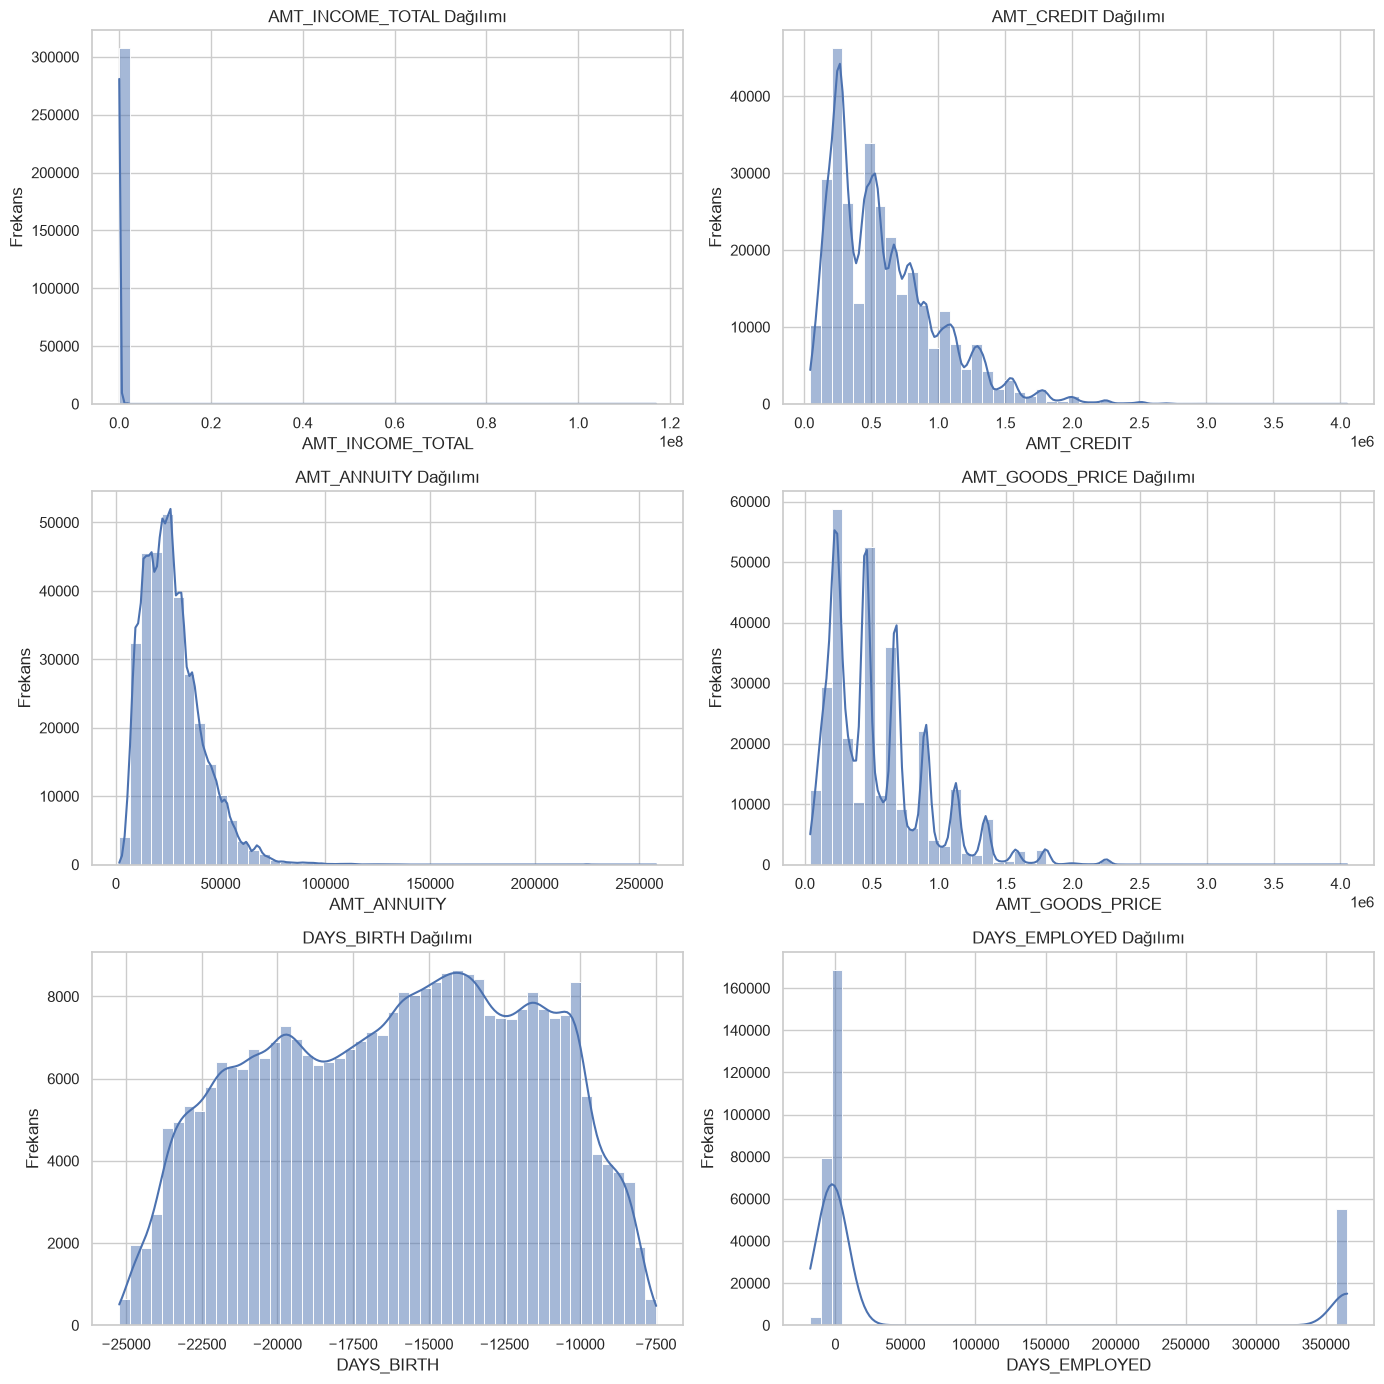

In [11]:
# İncelenecek sayısal değişkenler
selected_numeric = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

# Tanımlayıcı istatistikler
display(
    df[selected_numeric].describe().T.round(2)
)

# Dağılım grafikleri
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for i, column in enumerate(selected_numeric):
    sns.histplot(
        data=df,
        x=column,
        bins=50,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"{column} Dağılımı")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frekans")

plt.tight_layout()
plt.show()

**Şekil 4. Seçilen Sayısal Değişkenlerin Dağılımları**

Sayısal değişkenlerin dağılımları incelendiğinde, finansal değişkenlerin çoğunda sağa çarpık dağılımlar gözlemlenmiştir. Özellikle AMT_INCOME_TOTAL değişkeninde ortalama ile medyan arasındaki farkın yüksek olması ve maksimum değerin 117.000.000 seviyesine ulaşması dikkat çekmektedir.

DAYS_BIRTH değişkeni negatif değerlerden oluşmakta olup gün cinsinden kodlanan doğum zamanı bilgisini temsil etmektedir. DAYS_EMPLOYED değişkeninde ise 365.243 değerinde belirgin bir yoğunlaşma görülmüştür. Bu değerin özel bir kodlama olup olmadığı veri sözlüğü üzerinden araştırılacaktır. Bu aşamada herhangi bir uç değer silme veya dönüştürme işlemi yapılmamıştır.

In [12]:
# DAYS_EMPLOYED değişkeninin veri sözlüğündeki açıklaması

display(
    feature_dictionary.loc[
        feature_dictionary["Feature"] == "DAYS_EMPLOYED",
        ["Feature", "Meaning", "Notes"]
    ]
)

# Özel değerin frekansını inceleme
special_value = 365243

print(
    "365243 değerinin kayıt sayısı:",
    (df["DAYS_EMPLOYED"] == special_value).sum()
)

print(
    "365243 değerinin oranı (%):",
    round((df["DAYS_EMPLOYED"] == special_value).mean() * 100, 2)
)

# Değerin TARGET ile ilişkisini inceleme
display(
    pd.crosstab(
        df["DAYS_EMPLOYED"] == special_value,
        df["TARGET"],
        normalize="index"
    ).round(4) * 100
)

,Feature,Meaning,Notes
18,DAYS_EMPLOYED,How many days before the application the perso...,time only relative to the application


365243 değerinin kayıt sayısı: 55374
365243 değerinin oranı (%): 18.01


TARGET,0,1
DAYS_EMPLOYED,,
False,91.34,8.66
True,94.60,5.40


**DAYS_EMPLOYED Değişkeninin İncelenmesi**

DAYS_EMPLOYED değişkeninde 365243 değerinin 55.374 gözlemde bulunduğu ve toplam verinin %18,01'ini oluşturduğu belirlenmiştir. Veri sözlüğünde değişken, başvuru sahibinin mevcut işine başvuru tarihinden kaç gün önce başladığını ifade etmektedir. İncelenen özel değer için TARGET=1 oranı %5,40 iken diğer gözlemlerde bu oran %8,66'dır. Bu farklılık, söz konusu değerin ayrı bir grup olarak değerlendirilmesinin yararlı olabileceğine işaret etmektedir. Bu nedenle ilgili gözlemlerin silinmesi yerine özel bir gösterge değişkeni oluşturulması ve alternatif ön işleme yaklaşımlarının model performansı üzerinden karşılaştırılması planlanmıştır.

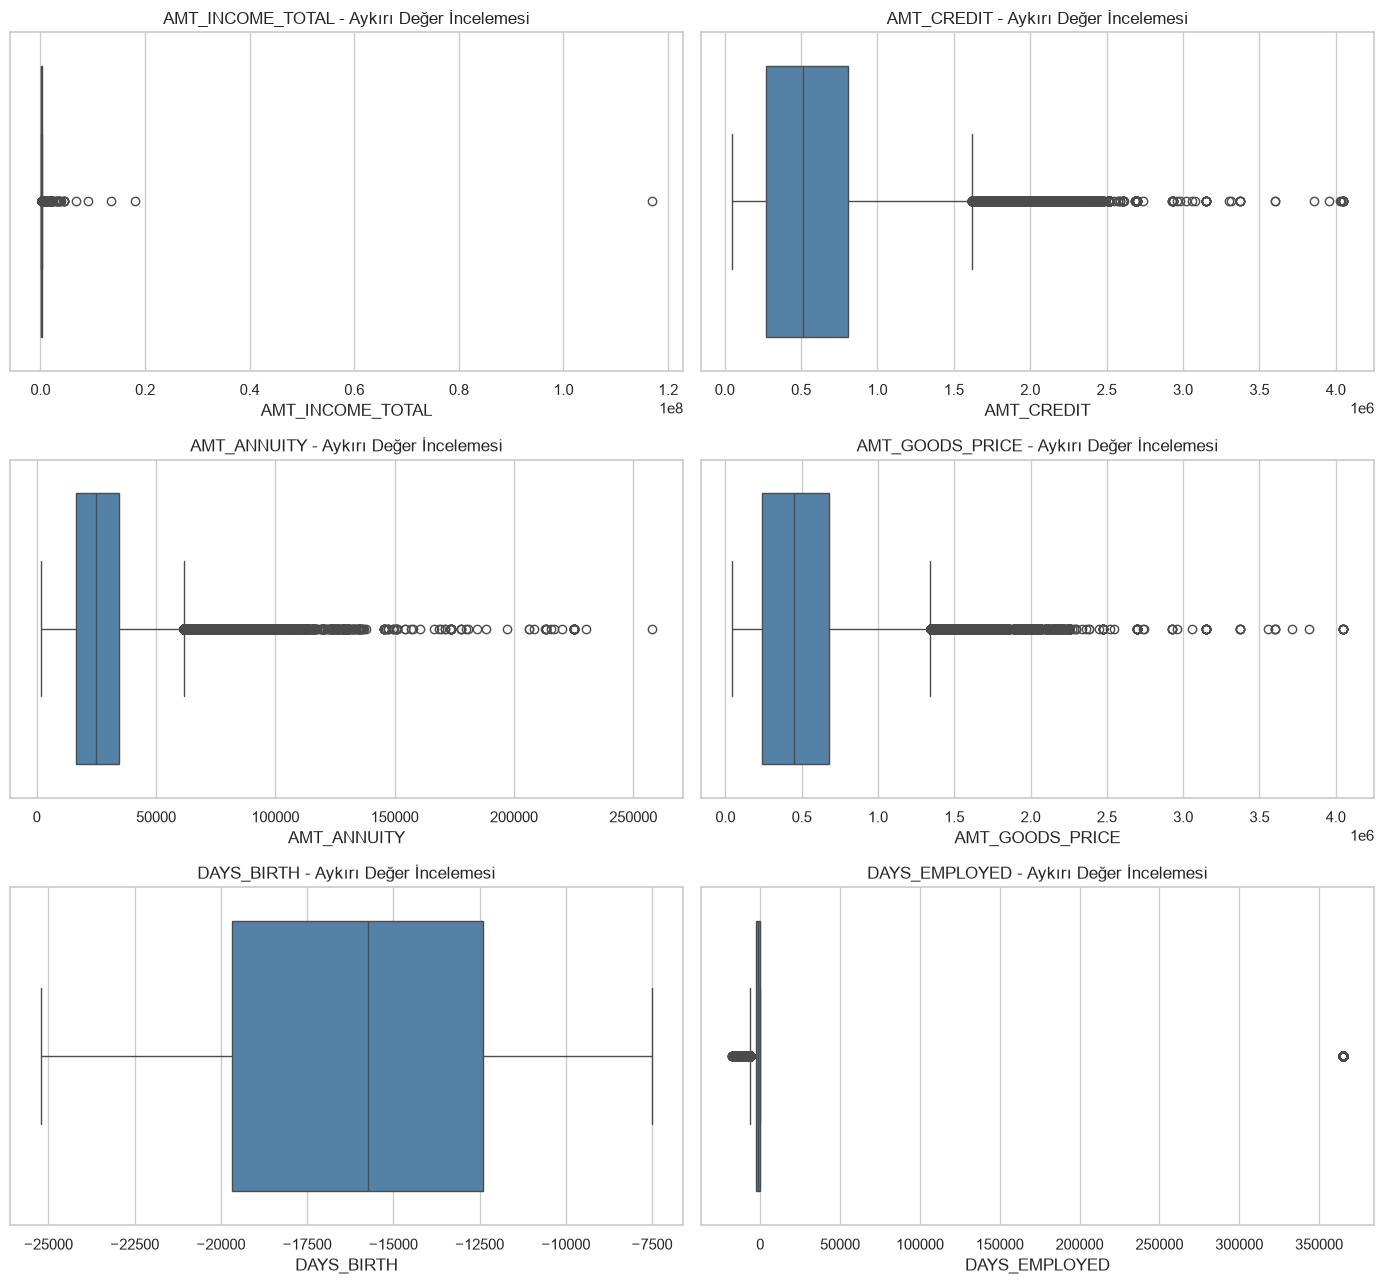

In [13]:
# Seçilen sayısal değişkenlerin kutu grafikleri

fig, axes = plt.subplots(3, 2, figsize=(14, 13))
axes = axes.flatten()

for i, column in enumerate(selected_numeric):
    sns.boxplot(
        data=df,
        x=column,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"{column} - Aykırı Değer İncelemesi")
    axes[i].set_xlabel(column)

plt.tight_layout()
plt.show()

### 3.5. IQR Yöntemiyle Aykırı Değerlerin Belirlenmesi

In [14]:
# IQR yöntemiyle potansiyel aykırı değer analizi

outlier_results = []

for column in selected_numeric:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_results.append({
        "Değişken": column,
        "Alt Sınır": round(lower_bound, 2),
        "Üst Sınır": round(upper_bound, 2),
        "Aykırı Gözlem Sayısı": int(outlier_count),
        "Aykırı Gözlem Oranı (%)": round(
            outlier_count / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(
    outlier_summary.sort_values(
        "Aykırı Gözlem Sayısı",
        ascending=False
    )
)

,Değişken,Alt Sınır,Üst Sınır,Aykırı Gözlem Sayısı,Aykırı Gözlem Oranı (%)
5,DAYS_EMPLOYED,-6466.5,3417.5,72217,23.48
3,AMT_GOODS_PRICE,-423000.0,1341000.0,14728,4.79
0,AMT_INCOME_TOTAL,-22500.0,337500.0,14035,4.56
2,AMT_ANNUITY,-10584.0,61704.0,7504,2.44
1,AMT_CREDIT,-537975.0,1616625.0,6562,2.13
4,DAYS_BIRTH,-30585.5,-1509.5,0,0.00


**IQR Yöntemiyle Aykırı Değer Analizi**

IQR yöntemi kullanılarak seçilen altı sayısal değişkendeki potansiyel aykırı gözlemler incelenmiştir. En yüksek aykırı gözlem oranı %23,48 ile DAYS_EMPLOYED değişkeninde belirlenmiştir. Bunu %4,79 ile AMT_GOODS_PRICE ve %4,56 ile AMT_INCOME_TOTAL değişkenleri izlemiştir. DAYS_BIRTH değişkeninde ise IQR sınırlarının dışında gözlem tespit edilmemiştir. Bununla birlikte, finansal değişkenlerde belirlenen uç değerlerin gerçek gözlemler olabileceği dikkate alınarak otomatik silme işleminden kaçınılmıştır. DAYS_EMPLOYED değişkenindeki özel 365243 değeri ayrıca değerlendirilmiştir.

### 3.6. Kategorik Değişkenlerin Dağılımı

In [15]:
# İncelenecek kategorik değişkenler
selected_categorical = [
    "CODE_GENDER",
    "NAME_CONTRACT_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS"
]

# Kategorik değişkenlerin genel dağılımı
for column in selected_categorical:

    print(f"\n{'=' * 55}")
    print(f"Değişken: {column}")
    print(f"Toplam kategori sayısı: {df[column].nunique()}")
    print(f"Eksik değer sayısı: {df[column].isna().sum()}")

    frequency = (
        df[column]
        .value_counts(dropna=False)
        .head(10)
        .to_frame("Kayıt Sayısı")
    )

    frequency["Oran (%)"] = (
        df[column]
        .value_counts(normalize=True, dropna=False)
        .head(10) * 100
    ).round(2)

    display(frequency)


Değişken: CODE_GENDER
Toplam kategori sayısı: 3
Eksik değer sayısı: 0


,Kayıt Sayısı,Oran (%)
CODE_GENDER,,
F,202448,65.83
M,105059,34.16
XNA,4,0.00



Değişken: NAME_CONTRACT_TYPE
Toplam kategori sayısı: 2
Eksik değer sayısı: 0


,Kayıt Sayısı,Oran (%)
NAME_CONTRACT_TYPE,,
Cash loans,278232,90.48
Revolving loans,29279,9.52



Değişken: NAME_INCOME_TYPE
Toplam kategori sayısı: 8
Eksik değer sayısı: 0


,Kayıt Sayısı,Oran (%)
NAME_INCOME_TYPE,,
Working,158774,51.63
Commercial associate,71617,23.29
Pensioner,55362,18.00
State servant,21703,7.06
Unemployed,22,0.01
Student,18,0.01
Businessman,10,0.00
Maternity leave,5,0.00



Değişken: NAME_EDUCATION_TYPE
Toplam kategori sayısı: 5
Eksik değer sayısı: 0


,Kayıt Sayısı,Oran (%)
NAME_EDUCATION_TYPE,,
Secondary / secondary special,218391,71.02
Higher education,74863,24.34
Incomplete higher,10277,3.34
Lower secondary,3816,1.24
Academic degree,164,0.05



Değişken: NAME_FAMILY_STATUS
Toplam kategori sayısı: 6
Eksik değer sayısı: 0


,Kayıt Sayısı,Oran (%)
NAME_FAMILY_STATUS,,
Married,196432,63.88
Single / not married,45444,14.78
Civil marriage,29775,9.68
Separated,19770,6.43
Widow,16088,5.23
Unknown,2,0.00


### 3.7. Kategorik Değişkenlerin Hedef Değişkenle İlişkisi

In [16]:
# Kategorik değişkenlerin TARGET ile ilişkisi

for column in selected_categorical:

    print(f"\n{'=' * 60}")
    print(f"{column} - Hedef Değişken İlişkisi")

    target_analysis = (
        df.groupby(column, observed=False)
        .agg(
            Kayit_Sayisi=("TARGET", "size"),
            Riskli_Kayit_Orani=("TARGET", "mean")
        )
        .sort_values("Riskli_Kayit_Orani", ascending=False)
    )

    target_analysis["Riskli_Kayit_Orani"] = (
        target_analysis["Riskli_Kayit_Orani"] * 100
    ).round(2)

    display(target_analysis)


CODE_GENDER - Hedef Değişken İlişkisi


,Kayit_Sayisi,Riskli_Kayit_Orani
CODE_GENDER,,
M,105059,10.14
F,202448,7.00
XNA,4,0.00



NAME_CONTRACT_TYPE - Hedef Değişken İlişkisi


,Kayit_Sayisi,Riskli_Kayit_Orani
NAME_CONTRACT_TYPE,,
Cash loans,278232,8.35
Revolving loans,29279,5.48



NAME_INCOME_TYPE - Hedef Değişken İlişkisi


,Kayit_Sayisi,Riskli_Kayit_Orani
NAME_INCOME_TYPE,,
Maternity leave,5,40.00
Unemployed,22,36.36
Working,158774,9.59
Commercial associate,71617,7.48
State servant,21703,5.75
Pensioner,55362,5.39
Businessman,10,0.00
Student,18,0.00



NAME_EDUCATION_TYPE - Hedef Değişken İlişkisi


,Kayit_Sayisi,Riskli_Kayit_Orani
NAME_EDUCATION_TYPE,,
Lower secondary,3816,10.93
Secondary / secondary special,218391,8.94
Incomplete higher,10277,8.48
Higher education,74863,5.36
Academic degree,164,1.83



NAME_FAMILY_STATUS - Hedef Değişken İlişkisi


,Kayit_Sayisi,Riskli_Kayit_Orani
NAME_FAMILY_STATUS,,
Civil marriage,29775,9.94
Single / not married,45444,9.81
Separated,19770,8.19
Married,196432,7.56
Widow,16088,5.82
Unknown,2,0.00


### Kategorik Değişkenlerin Hedef Değişkenle İlişkisi

Kategorik değişkenlerin TARGET değişkeniyle ilişkisi incelendiğinde, kategoriler arasında geri ödeme güçlüğü gözlenme oranlarının farklılaştığı belirlenmiştir. CODE_GENDER değişkeninde M kategorisinin riskli kayıt oranı %10,14, F kategorisinin ise %7,00 olarak hesaplanmıştır. NAME_EDUCATION_TYPE değişkeninde Lower secondary kategorisinde %10,93, Higher education kategorisinde %5,36 oranında TARGET=1 gözlenmiştir. NAME_INCOME_TYPE değişkeninde Working kategorisinin oranı %9,59, Pensioner kategorisinin oranı ise %5,39'dur.

Bununla birlikte, bazı kategorilerin çok az sayıda gözlem içermesi nedeniyle yüksek veya düşük oranların genellenebilirliği sınırlıdır. Bu nedenle kategorik değişkenler modelleme aşamasında değerlendirilirken kategori frekansları da dikkate alınacaktır. Elde edilen sonuçlar değişkenler ile hedef arasında gözlemsel ilişkiler göstermekte olup nedensel bir yorum olarak değerlendirilmemelidir.

### 3.8. Kategorik Değişkenlerde Risk Oranlarının Görselleştirilmesi

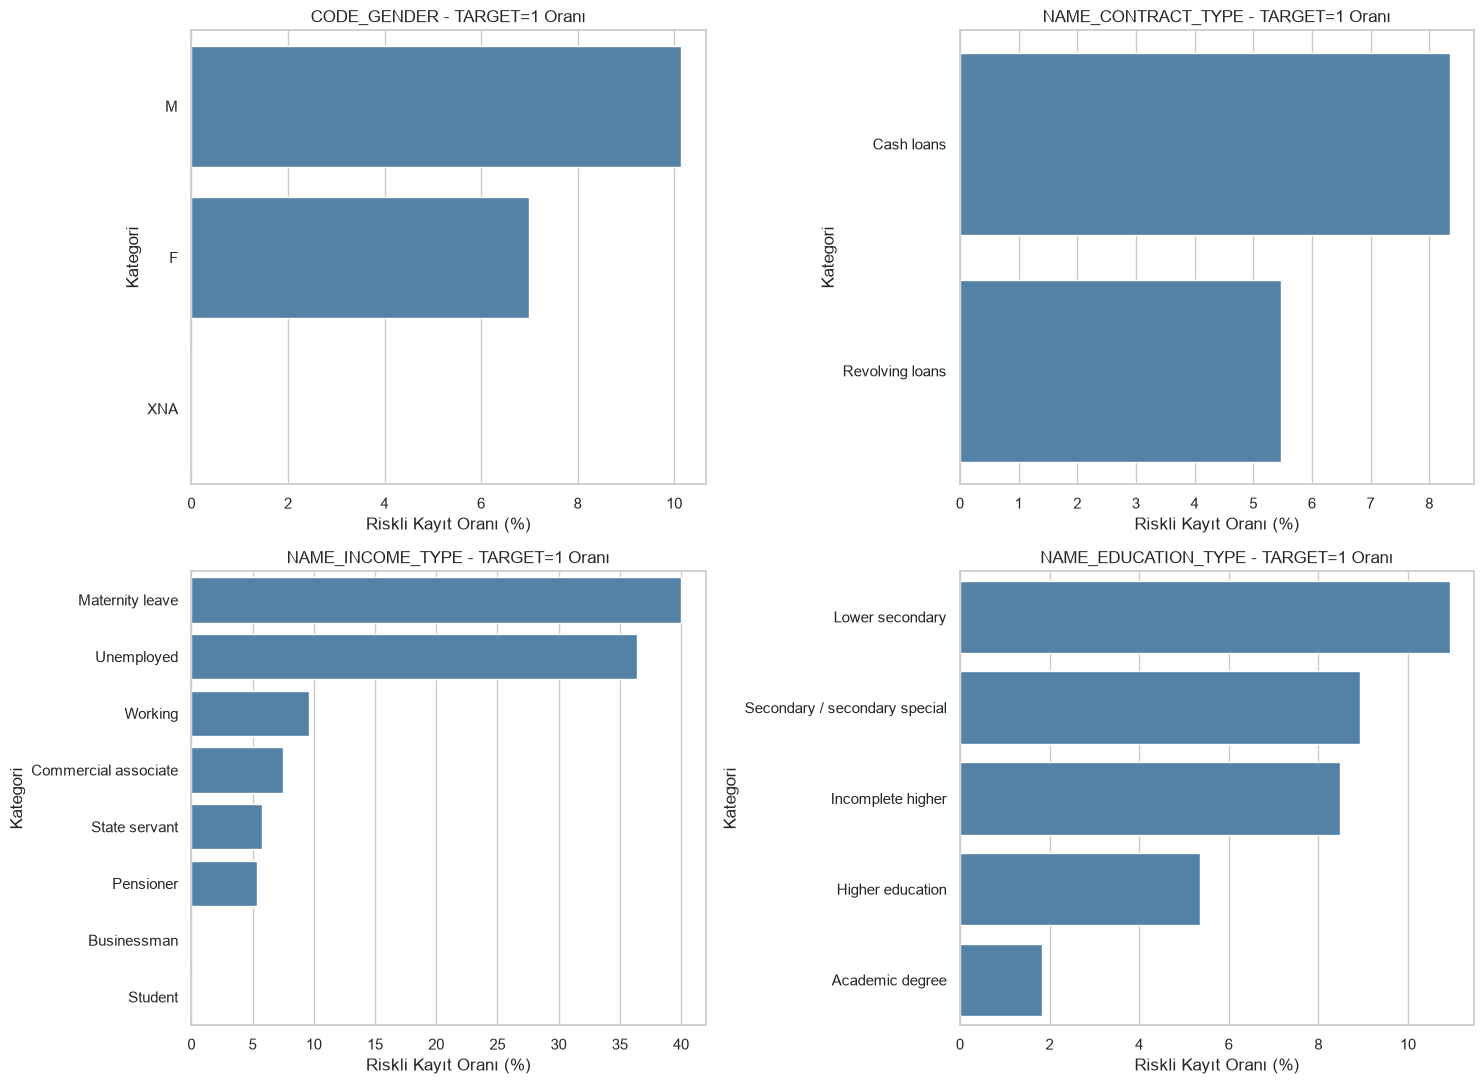

In [17]:
# Kategorik değişkenlerde TARGET=1 oranlarının karşılaştırılması

plot_categories = [
    "CODE_GENDER",
    "NAME_CONTRACT_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE"
]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
axes = axes.flatten()

for i, column in enumerate(plot_categories):

    risk_rates = (
        df.groupby(column, observed=False)["TARGET"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
        .reset_index()
    )

    sns.barplot(
        data=risk_rates,
        x="TARGET",
        y=column,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"{column} - TARGET=1 Oranı")
    axes[i].set_xlabel("Riskli Kayıt Oranı (%)")
    axes[i].set_ylabel("Kategori")

plt.tight_layout()
plt.show()

### 3.9. Sayıs### 3.9. Sayısal Değişkenlerin Hedef Değişkene Göre Karşılaştırılması

Bu bölümde, sayısal değişkenlerin hedef değişkenle ilişkisi incelenmiştir. Geri ödeme güçlüğü yaşayan ve yaşamayan müşterilerin finansal ve demografik özellikleri karşılaştırılarak gruplar arasındaki dağılım farklılıkları araştırılmıştır.al Değişkenlerin Hedef Değişkene Göre Karşılaştırılması

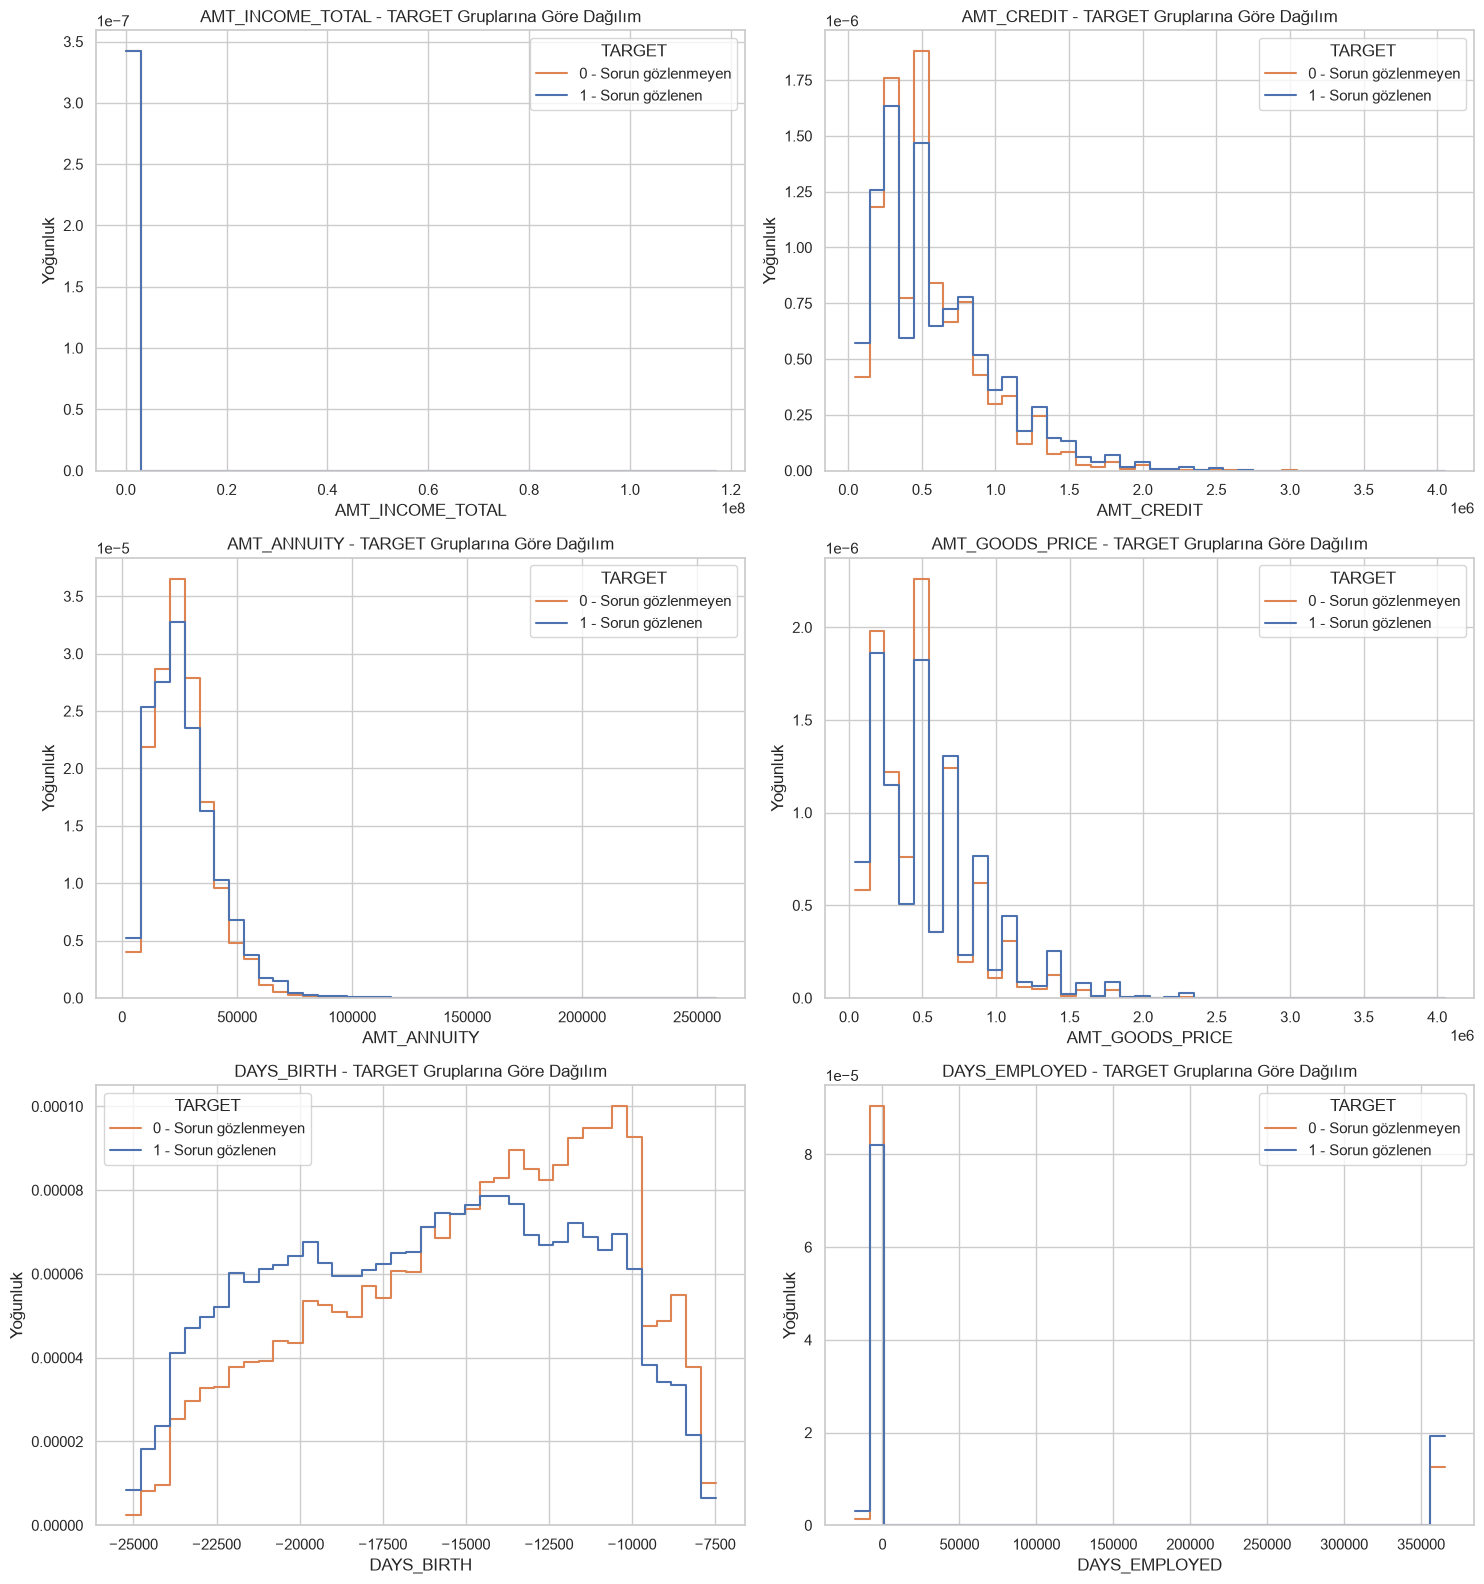

TARGET                           0          1
AMT_INCOME_TOTAL mean    169077.72  165611.76
                 median  148500.00  135000.00
AMT_CREDIT       mean    602648.28  557778.53
                 median  517788.00  497520.00
AMT_ANNUITY      mean     27163.62   26481.74
                 median   24876.00   25263.00
AMT_GOODS_PRICE  mean    542736.80  488972.41
                 median  450000.00  450000.00
DAYS_BIRTH       mean    -16138.18  -14884.83
                 median  -15877.00  -14282.00
DAYS_EMPLOYED    mean     65696.15   42394.68
                 median   -1235.00   -1034.00

In [18]:
# Hedef değişkene göre sayısal değişkenlerin karşılaştırılması

selected_numeric = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

# Her iki hedef sınıfı için dağılım grafikleri
fig, axes = plt.subplots(3, 2, figsize=(15, 16))
axes = axes.flatten()

for i, column in enumerate(selected_numeric):
    sns.histplot(
        data=df,
        x=column,
        hue="TARGET",
        bins=40,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        ax=axes[i]
    )

    axes[i].set_title(f"{column} - TARGET Gruplarına Göre Dağılım")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Yoğunluk")
    axes[i].legend(
        title="TARGET",
        labels=["0 - Sorun gözlenmeyen", "1 - Sorun gözlenen"]
    )

plt.tight_layout()
plt.show()

# Gruplara göre tanımlayıcı istatistikler
comparison = (
    df.groupby("TARGET")[selected_numeric]
    .agg(["mean", "median"])
    .T
)

display(comparison.round(2))

### 3.10. Keşifsel Veri Analizi Genel Değerlendirmesi

Keşifsel veri analizi sonucunda veri setinde belirgin bir sınıf dengesizliği, sayısal ve kategorik değişkenlerde eksik değerler ve bazı sayısal değişkenlerde uç değerler tespit edilmiştir. Ayrıca hedef değişken ile bazı kategorik ve sayısal değişkenler arasında gözlemsel farklılıklar görülmüştür.

Özellikle DAYS_EMPLOYED değişkeninde 365243 değerinin özel bir kod olabileceği belirlenmiştir. Finansal değişkenlerde ise sağa çarpık dağılımlar gözlenmiştir.

Bu bulgular, modelleme öncesinde eksik değer yönetimi, kategorik değişkenlerin kodlanması, sayısal değişkenlerin ölçeklendirilmesi ve özel değerlerin ele alınması gibi ön işleme adımlarının gerekli olduğunu göstermektedir.